# Lab 6 — Data Preprocessing for Machine Learning
**Course:** Programming for AI  |  **Dataset:** Bank Customer Churn  |  **Target:** `Exited` (1 = left, 0 = stayed)

## Setup

In [1]:
# !pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn pyod
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

df = pd.read_csv("../dataset/bank_churn.csv")   # change to "bank_churn.csv" if the CSV is next to the notebook

# This CSV uses snake_case headers; rename them to the lab's column names
df = df.rename(columns={"customer_id": "CustomerId", "credit_score": "CreditScore", "country": "Geography",
                        "gender": "Gender", "age": "Age", "tenure": "Tenure", "balance": "Balance",
                        "products_number": "NumOfProducts", "credit_card": "HasCrCard",
                        "active_member": "IsActiveMember", "estimated_salary": "EstimatedSalary", "churn": "Exited"})
print(df.shape)
df.head()

(10000, 12)


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   CreditScore      10000 non-null  int64  
 2   Geography        10000 non-null  str    
 3   Gender           10000 non-null  str    
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  int64  
 8   HasCrCard        10000 non-null  int64  
 9   IsActiveMember   10000 non-null  int64  
 10  EstimatedSalary  10000 non-null  float64
 11  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 937.6 KB


CustomerId         0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

## Part 1 — Feature Selection

### Task 1: Correlation heatmap

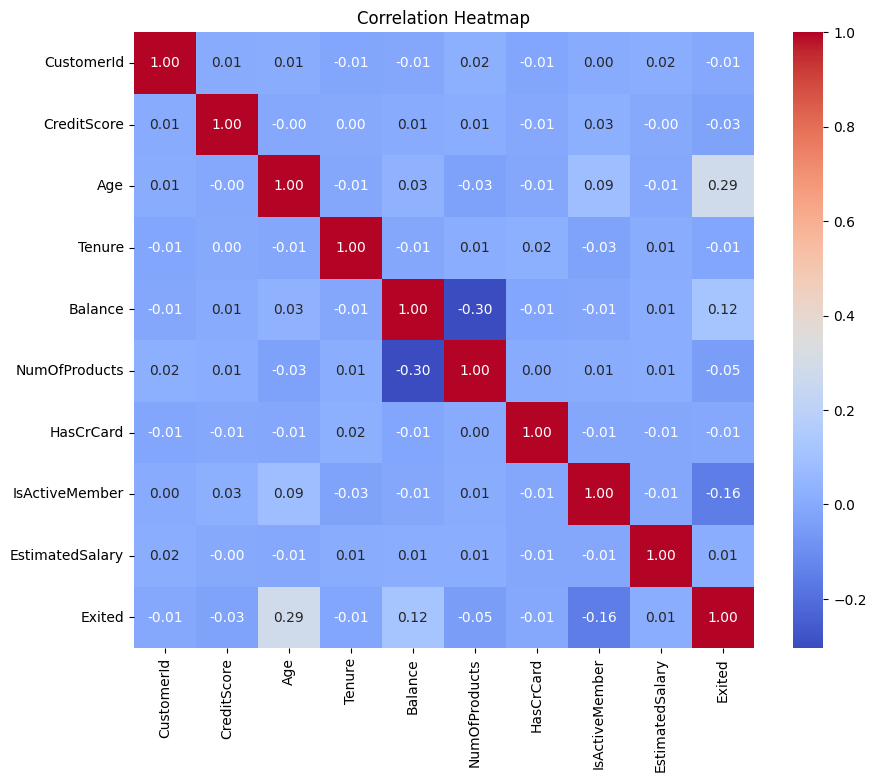

In [3]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Q1. Which features are highly correlated?**  
No pair of input features is strongly correlated (nothing above 0.8). The strongest relationship between two inputs is `Balance` ↔ `NumOfProducts` at **−0.30** (moderate, negative). With the target `Exited`, the highest correlations are `Age` (**+0.29**), `IsActiveMember` (**−0.16**) and `Balance` (**+0.12**). `CustomerId` is just an identifier and has essentially zero correlation with everything.

### Task 2: Correlation with the target

In [4]:
df.corr(numeric_only=True)['Exited'].sort_values()

IsActiveMember    -0.156128
NumOfProducts     -0.047820
CreditScore       -0.027094
Tenure            -0.014001
HasCrCard         -0.007138
CustomerId        -0.006248
EstimatedSalary    0.012097
Balance            0.118533
Age                0.285323
Exited             1.000000
Name: Exited, dtype: float64

### Task 3: Features with correlation > 0.1 or < −0.1

In [5]:
corr_target = df.corr(numeric_only=True)['Exited'].drop('Exited')
selected = corr_target[(corr_target > 0.1) | (corr_target < -0.1)]
print("Selected features:")
print(selected.sort_values())
selected_features = selected.index.tolist()
selected_features

Selected features:
IsActiveMember   -0.156128
Balance           0.118533
Age               0.285323
Name: Exited, dtype: float64


['Age', 'Balance', 'IsActiveMember']

### Task 4 (Challenge): Remove redundant features

In [6]:
# 1) Identifier columns carry no predictive information
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], errors='ignore')

# 2) Check for highly correlated feature pairs (|r| > 0.8)
cm = df.drop(columns='Exited').corr(numeric_only=True).abs()
upper = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
high_pairs = [(a, b, round(upper.loc[a, b], 2)) for a in upper.index for b in upper.columns
              if pd.notna(upper.loc[a, b]) and upper.loc[a, b] > 0.8]
print("Highly correlated pairs:", high_pairs if high_pairs else "none")
df.head()

Highly correlated pairs: none


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Why does removing redundant features help prevent overfitting?**  
Redundant or irrelevant features add dimensions without adding new information. With more features, the model has more freedom to fit noise and random quirks of the training set (e.g. memorising a `CustomerId`) instead of real patterns, so it scores well on training data but poorly on unseen data. Removing them reduces model complexity and variance, avoids multicollinearity (unstable coefficients in linear models), and speeds up training.

## Part 2 — Handling Imbalanced Data

In [7]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [8]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

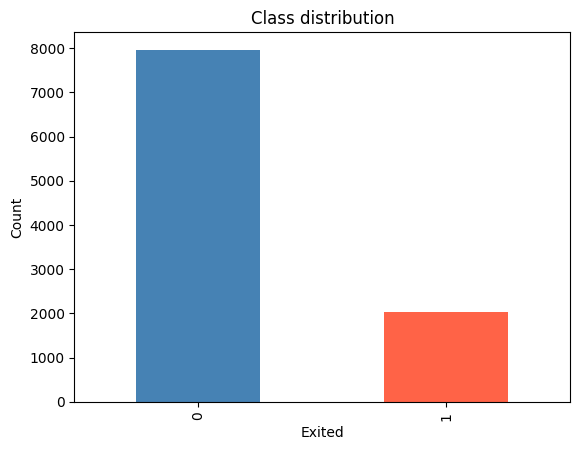

In [9]:
df['Exited'].value_counts().plot(kind='bar', color=['steelblue','tomato'])
plt.title("Class distribution"); plt.xlabel("Exited"); plt.ylabel("Count"); plt.show()

**Q. Is the dataset balanced or imbalanced?**  
**Imbalanced.** About **79.6%** of customers stayed (0) and only **20.4%** left (1) — a ratio of about 4:1 (7,963 vs 2,037 rows). A model that always predicts “stayed” would already reach ~80% accuracy while catching no churners.

### Task 3: Upsampling

In [10]:
def upsample(features, target, repeat):
    features_0 = features[target == 0]
    features_1 = features[target == 1]
    target_0 = target[target == 0]
    target_1 = target[target == 1]
    features_up = pd.concat([features_0] + [features_1] * repeat)
    target_up = pd.concat([target_0] + [target_1] * repeat)
    features_up, target_up = shuffle(features_up, target_up, random_state=42)
    return features_up, target_up

features = df.drop("Exited", axis=1)
target = df["Exited"]
features_up, target_up = upsample(features, target, 3)

### Task 4: Class distribution after upsampling

In [11]:
print(target_up.value_counts())
print()
print(target_up.value_counts(normalize=True) * 100)

Exited
0    7963
1    6111
Name: count, dtype: int64

Exited
0    56.579508
1    43.420492
Name: proportion, dtype: float64


### Task 5 (Challenge): Downsampling

In [12]:
def downsample(features, target, fraction):
    """Randomly keep `fraction` of the majority class (0) and all of the minority class (1)."""
    features_0 = features[target == 0]
    features_1 = features[target == 1]
    target_0 = target[target == 0]
    target_1 = target[target == 1]
    features_down = pd.concat([features_0.sample(frac=fraction, random_state=42), features_1])
    target_down = pd.concat([target_0.sample(frac=fraction, random_state=42), target_1])
    return shuffle(features_down, target_down, random_state=42)

features_down, target_down = downsample(features, target, 0.25)
print(target_down.value_counts())
print(target_down.value_counts(normalize=True) * 100)

Exited
1    2037
0    1991
Name: count, dtype: int64
Exited
1    50.571003
0    49.428997
Name: proportion, dtype: float64


**Note:** Upsampling duplicates minority rows (no information lost, but risk of overfitting to repeated rows); downsampling discards majority rows (balanced and fast, but loses data). In the final pipeline below, balancing is applied **only to the training set after splitting**, otherwise duplicated rows can leak into the validation/test sets.

## Outlier Detection and Removal (lab objective)

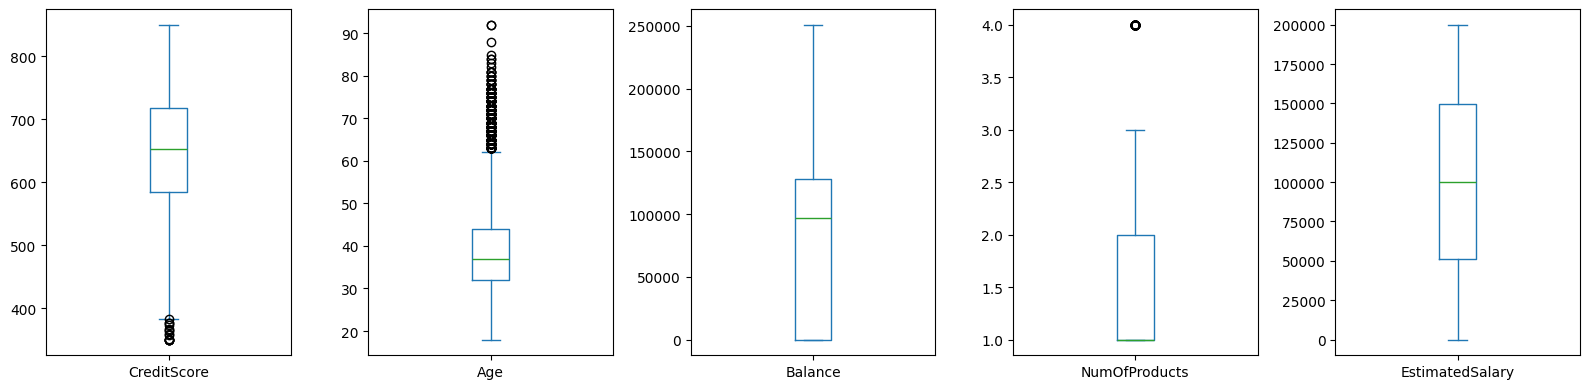

CreditScore      bounds=(383.0, 919.0)  outliers=15
Age              bounds=(14.0, 62.0)  outliers=359
Balance          bounds=(-191,466.4, 319,110.6)  outliers=0
NumOfProducts    bounds=(-0.5, 3.5)  outliers=60
EstimatedSalary  bounds=(-96,577.1, 296,967.5)  outliers=0


In [13]:
num_cols = ['CreditScore', 'Age', 'Balance', 'NumOfProducts', 'EstimatedSalary']
df[num_cols].plot(kind='box', subplots=True, layout=(1,5), figsize=(16,4), sharey=False)
plt.tight_layout(); plt.show()

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    print(f"{c:16s} bounds=({lo:,.1f}, {hi:,.1f})  outliers={(~df[c].between(lo, hi)).sum()}")

In [14]:
# Remove outliers from CreditScore and Age (Balance and EstimatedSalary have no IQR outliers, and NumOfProducts is a small discrete count)
before = len(df)
mask = pd.Series(True, index=df.index)
for c in ['CreditScore', 'Age']:
    lo, hi = iqr_bounds(df[c])
    mask &= df[c].between(lo, hi)
df = df[mask].reset_index(drop=True)
print(f"Rows: {before} -> {len(df)} (removed {before-len(df)})")

Rows: 10000 -> 9626 (removed 374)


In [15]:
# Optional: model-based outlier detection with PyOD
try:
    from pyod.models.iforest import IForest
    det = IForest(contamination=0.02, random_state=42).fit(df[num_cols])
    print("PyOD IForest flagged:", int(det.labels_.sum()), "rows (not removed)")
except ImportError:
    print("pyod not installed - skipping optional step")

pyod not installed - skipping optional step


## Part 3 — Encoding Categorical Variables

In [16]:
df.select_dtypes(include=['object', 'string']).head()

,Geography,Gender
0,France,Female
1,Spain,Female
2,France,Female
3,France,Female
4,Spain,Female


In [17]:
n_cols_before = df.shape[1]
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)
print("Columns before:", n_cols_before, "| after:", df.shape[1])

Columns before: 11 | after: 12


In [18]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


**Q. How many new columns were created?**  
**3 new columns:** `Geography_Germany`, `Geography_Spain` (Geography has 3 values → 3−1 = 2 dummies, France is the dropped baseline) and `Gender_Male` (2 values → 1 dummy). The 2 original columns were removed, so the total column count increases by 1.

### Task 4 (Challenge): Ordinal vs. One-hot encoding
| | **Ordinal encoding** | **One-hot encoding** |
|---|---|---|
| What it does | Maps each category to one integer (e.g. Low=1, Medium=2, High=3) | Creates one binary (0/1) column per category |
| Implies order? | **Yes** — the numbers have rank/distance | **No** — all categories are treated as equal |
| Use for | **Ordinal** data with a real order (education level, rating, size S/M/L) | **Nominal** data with no order (Geography, Gender, colour) |
| Columns | 1 column | k columns (k−1 with `drop_first=True`) |
| Risk | On nominal data, the model wrongly assumes France < Germany < Spain | More columns (high-cardinality features can blow up dimensionality) |

## Part 4 — Data Splitting

In [19]:
# 60% train / 20% validation / 20% test
train_valid, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Exited'])
train, valid = train_test_split(train_valid, test_size=0.25, random_state=42, stratify=train_valid['Exited'])

In [20]:
X_train = train.drop("Exited", axis=1); y_train = train["Exited"]
X_valid = valid.drop("Exited", axis=1); y_valid = valid["Exited"]
X_test  = test.drop("Exited", axis=1);  y_test  = test["Exited"]

In [21]:
print("Training set  :", X_train.shape, y_train.shape)
print("Validation set:", X_valid.shape, y_valid.shape)
print("Test set      :", X_test.shape, y_test.shape)
print("\nChurn rate  train/valid/test:",
      round(y_train.mean(),3), round(y_valid.mean(),3), round(y_test.mean(),3))

Training set  : (5775, 11) (5775,)
Validation set: (1925, 11) (1925,)
Test set      : (1926, 11) (1926,)

Churn rate  train/valid/test: 0.202 0.203 0.202


`stratify` keeps the churn proportion the same in all three sets.

In [22]:
# Balance the TRAINING set only (after splitting, to avoid leakage)
X_train_bal, y_train_bal = upsample(X_train, y_train, 3)
print(y_train_bal.value_counts(normalize=True) * 100)

Exited
0    56.77308
1    43.22692
Name: proportion, dtype: float64


## Lab Reflection Questions

**1. Why is feature selection important?**  
It keeps only the variables that carry useful signal. This reduces overfitting (less noise to memorise), improves accuracy and generalisation, shortens training time, lowers memory/compute cost, and makes the model easier to interpret.

**2. What problems arise with imbalanced datasets?**  
The model becomes biased toward the majority class: it can reach high accuracy by always predicting “stayed” while missing almost every churner (poor recall/F1 on the minority class). Accuracy becomes a misleading metric, and the model sees too few minority examples to learn their pattern. Fixes: resampling (up/down-sampling, SMOTE), class weights, and metrics such as precision, recall, F1 and ROC-AUC.

**3. Why is one-hot encoding preferred for nominal variables?**  
Nominal categories (e.g. France, Germany, Spain) have no natural order. Integer labels would make the model assume an order and distances (Spain > Germany > France) that do not exist. One-hot encoding gives each category its own independent binary feature, so no false ranking is introduced.

**4. Why should test data never be used during training?**  
The test set simulates unseen, real-world data. If it influences training or tuning (data leakage), the performance estimate becomes over-optimistic and no longer reflects how the model will behave in production. Training is for fitting, validation for tuning, and test only for a single final evaluation.